In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data-3.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


In [3]:
print(df.dtypes)
df['Дата'] = pd.to_datetime(df['Дата'], dayfirst=True, errors='coerce')  # если день сначала


Дата            object
Склад            int64
Контрагент      object
Номенклатура    object
Количество       int64
dtype: object


Проверяем формат столбцов

In [4]:
# Посмотреть типы данных для всех столбцов
print(df.dtypes)

Дата            datetime64[ns]
Склад                    int64
Контрагент              object
Номенклатура            object
Количество               int64
dtype: object


Сразу переведем столбец "Дата" в правильный формат

In [5]:
df['Дата'] = pd.to_datetime(df['Дата'], errors='coerce')
print(df['Дата'].head())
print(df['Дата'].dtypes)

0   2018-01-04
1   2018-01-04
2   2018-01-04
3   2018-01-04
4   2018-01-04
Name: Дата, dtype: datetime64[ns]
datetime64[ns]


Сгруппируйте данные по дате, посчитайте количество продаж

In [6]:
grouped_df = df.groupby('Дата').size().reset_index(name='Количество продаж')
print(grouped_df.head())

        Дата  Количество продаж
0 2018-01-04               1840
1 2018-01-05               1301
2 2018-01-06               1306
3 2018-01-07               1322
4 2018-01-09               1719


Вывести несколько первых строк сгруппированных данных

In [7]:
print(grouped_df.head())

        Дата  Количество продаж
0 2018-01-04               1840
1 2018-01-05               1301
2 2018-01-06               1306
3 2018-01-07               1322
4 2018-01-09               1719


Нарисуйте график продаж у `grouped_df`

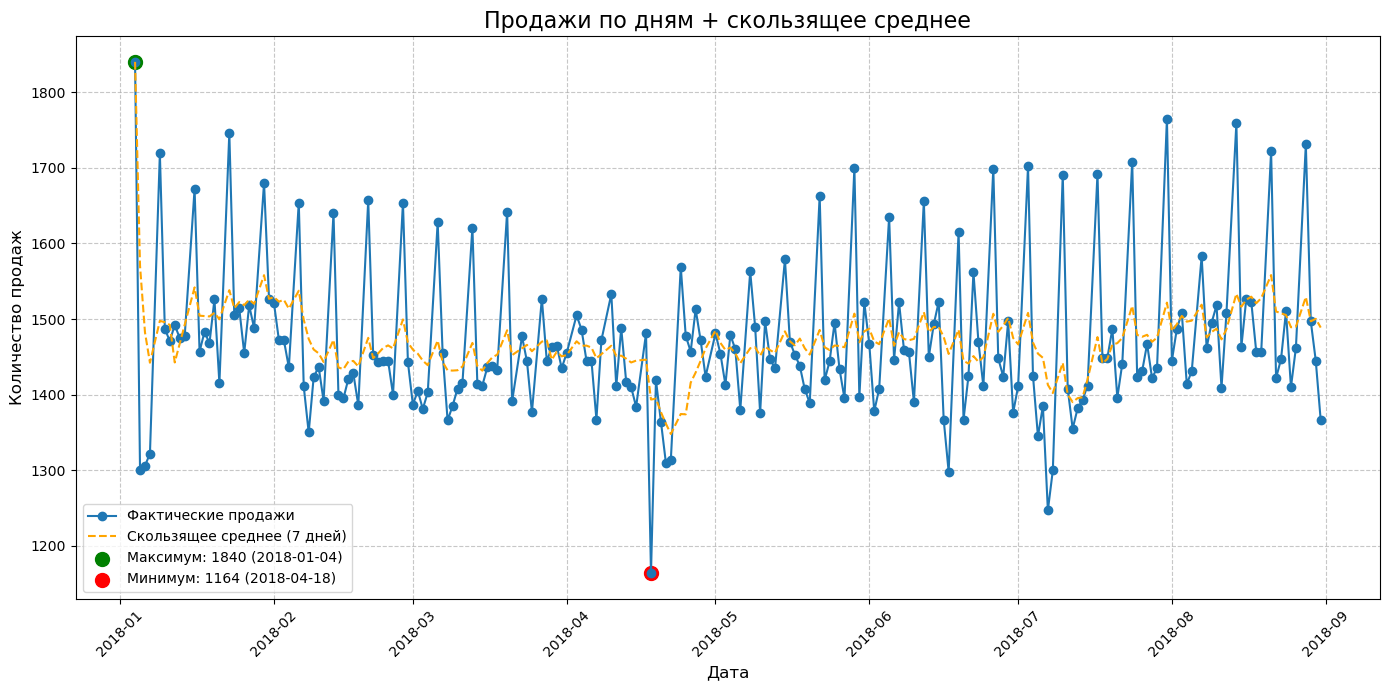

In [8]:
import matplotlib.pyplot as plt

# 1. Вычисляем скользящее среднее по 7 дням
grouped_df['Скользящее среднее'] = grouped_df['Количество продаж'].rolling(window=7, min_periods=1).mean()

# 2. Находим день с максимумом и минимумом продаж
max_row = grouped_df.loc[grouped_df['Количество продаж'].idxmax()]
min_row = grouped_df.loc[grouped_df['Количество продаж'].idxmin()]

# 3. Строим график
plt.figure(figsize=(14, 7))

# Линия фактических продаж
plt.plot(grouped_df['Дата'], grouped_df['Количество продаж'], label='Фактические продажи', marker='o')

# Линия скользящего среднего
plt.plot(grouped_df['Дата'], grouped_df['Скользящее среднее'], label='Скользящее среднее (7 дней)', linestyle='--', color='orange')

# Отметки максимума и минимума
plt.scatter(max_row['Дата'], max_row['Количество продаж'], color='green', s=100, label=f'Максимум: {max_row["Количество продаж"]} ({max_row["Дата"].date()})')
plt.scatter(min_row['Дата'], min_row['Количество продаж'], color='red', s=100, label=f'Минимум: {min_row["Количество продаж"]} ({min_row["Дата"].date()})')

# Настройка графика
plt.title('Продажи по дням + скользящее среднее', fontsize=16)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество продаж', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


Опишите что вы видите на графике. Ваша задача - максимально описать график

In [ ]:
Синяя линия показывает реальные продажи по дням — с резкими колебаниями.
Оранжевая пунктирная линия — сглаженная версия, даёт общее представление о тренде.
Зелёная точка — день с максимальными продажами, красная — с минимальными.
Такая визуализация помогает понять: когда были пики и падения, есть ли стабильный рост или сезонность.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [10]:
# Расчёт IQR
Q1 = grouped_df['Количество продаж'].quantile(0.25)
Q3 = grouped_df['Количество продаж'].quantile(0.75)
IQR = Q3 - Q1

# Границы для выбросов
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Фильтрация выбросов
outliers = grouped_df[(grouped_df['Количество продаж'] < lower_bound) | (grouped_df['Количество продаж'] > upper_bound)]

# Строка с максимальным выбросом
max_outlier = outliers.loc[outliers['Количество продаж'].idxmax()]
print("Максимальный выброс:")
print(max_outlier)


Максимальный выброс:
Дата                  2018-01-04 00:00:00
Количество продаж                    1840
Скользящее среднее                 1840.0
Name: 0, dtype: object


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [11]:
import pandas as pd

# Преобразуем колонку Дата в datetime, если ещё не
df['Дата'] = pd.to_datetime(df['Дата'], dayfirst=True)

# Добавим колонки: месяц и день недели
df['Месяц'] = df['Дата'].dt.month
df['День_недели'] = df['Дата'].dt.dayofweek  # 0=Пн, ..., 2=Ср

# Фильтрация по условиям:
filtered = df[
    (df['Склад'] == 3) &
    (df['Месяц'].isin([6, 7, 8])) &  # июнь, июль, август
    (df['День_недели'] == 2)         # среда
]

# Группируем по товару, считаем сумму проданного
top_item = (
    filtered.groupby('Номенклатура', as_index=False)['Количество']
    .sum()
    .sort_values(by='Количество', ascending=False)
)

# Выводим топ-1 товар
print("Топовый товар по продажам по средам за лето на складе 3:")
print(top_item.head(1))


Топовый товар по продажам по средам за лето на складе 3:
  Номенклатура  Количество
1    product_1        2267


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [12]:
import pandas as pd

# Попробуйте разные кодировки, например, 'latin1', 'cp1251', 'iso-8859-1'
weather = pd.read_csv('weather.csv', delimiter=';', encoding='utf-8') # Укажите вашу кодировку
# Оставим только нужные два столбца
weather = weather[['Дата', 'Средняя температура']].copy()

# Посмотрим результат
print(weather.head())

               Дата  Средняя температура
0  30.09.2018 23:00                  9.9
1  30.09.2018 20:00                 11.9
2  30.09.2018 17:00                 19.1
3  30.09.2018 14:00                 19.7
4  30.09.2018 11:00                 16.5


In [13]:
# Переименуем для удобства
weather.rename(columns={'Средняя температура': 'T'}, inplace=True)

print(weather.head())  # Проверка первых строк

               Дата     T
0  30.09.2018 23:00   9.9
1  30.09.2018 20:00  11.9
2  30.09.2018 17:00  19.1
3  30.09.2018 14:00  19.7
4  30.09.2018 11:00  16.5


In [14]:
grouped_df = df.groupby('Дата').size().reset_index(name='Количество продаж')
print(grouped_df.head())

        Дата  Количество продаж
0 2018-01-04               1840
1 2018-01-05               1301
2 2018-01-06               1306
3 2018-01-07               1322
4 2018-01-09               1719


In [15]:
print(grouped_df.columns.tolist())


['Дата', 'Количество продаж']


        Дата  Количество продаж        T
0 2018-01-04               1840 -14.0750
1 2018-01-05               1301 -16.8625
2 2018-01-06               1306 -13.3000
3 2018-01-07               1322 -12.7500
4 2018-01-09               1719  -6.2500


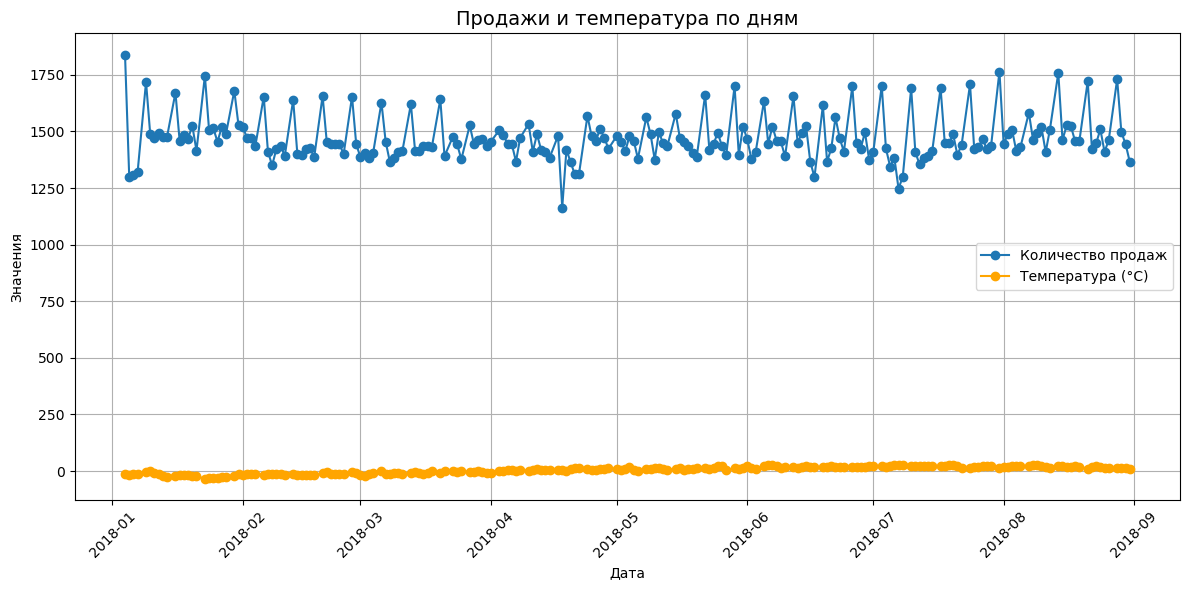

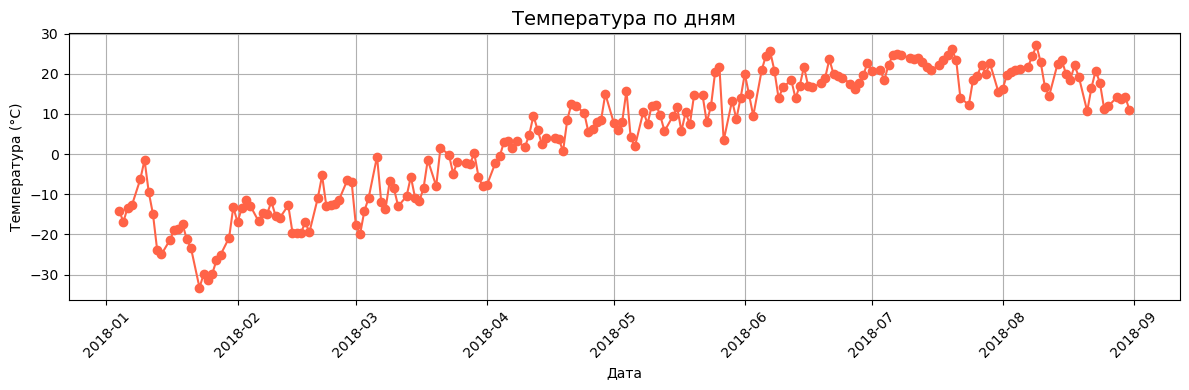

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Преобразуем даты
weather['Дата'] = pd.to_datetime(weather['Дата'], dayfirst=True)
weather['Дата'] = weather['Дата'].dt.normalize()  # убираем время (оставляем только день)

grouped_df['Дата'] = pd.to_datetime(grouped_df['Дата'])

# 2. Группируем температуру по дню (средняя за день)
daily_temp = weather.groupby('Дата', as_index=False)['T'].mean()

# 3. Объединяем таблицы
merged = pd.merge(grouped_df, daily_temp, on='Дата', how='left')

# 4. Проверим результат
print(merged.head())

# 5. График: продажи и температура
plt.figure(figsize=(12, 6))
plt.plot(merged['Дата'], merged['Количество продаж'], label='Количество продаж', marker='o')
plt.plot(merged['Дата'], merged['T'], label='Температура (°C)', marker='o', color='orange')
plt.title('Продажи и температура по дням', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Значения')
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Отдельный график температуры
plt.figure(figsize=(12, 4))
plt.plot(merged['Дата'], merged['T'], color='tomato', marker='o')
plt.title('Температура по дням', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
